In [ ]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from pathlib import Path
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy import stats
from scipy.stats import f_oneway, kruskal, mannwhitneyu, ttest_ind
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
from patsy import build_design_matrices

In [2]:

sm.show_versions()


INSTALLED VERSIONS
------------------
Python: 3.12.3.final.0
OS: Linux 7.0.0-43-generic #43~24.04.1-Ubuntu SMP PREEMPT_DYNAMIC Sat Oct 31 06:52:47 UTC 2 x86_64
byteorder: little
LC_ALL: None
LANG: en_US.UTF-8

statsmodels

Installed: 0.14.6 (/home/pkumar/simuscale-venv/lib/python3.12/site-packages/statsmodels)

Required Dependencies

cython: Not installed
numpy: 2.4.4 (/home/pkumar/simuscale-venv/lib/python3.12/site-packages/numpy)
scipy: 1.17.1 (/home/pkumar/simuscale-venv/lib/python3.12/site-packages/scipy)
pandas: 3.0.2 (/home/pkumar/simuscale-venv/lib/python3.12/site-packages/pandas)
    dateutil: 2.9.0.post0 (/home/pkumar/simuscale-venv/lib/python3.12/site-packages/dateutil)
patsy: 1.0.2 (/home/pkumar/simuscale-venv/lib/python3.12/site-packages/patsy)

Optional Dependencies

matplotlib: 3.10.8 (/home/pkumar/simuscale-venv/lib/python3.12/site-packages/matplotlib)
    backend: module://matplotlib_inline.backend_inline 
cvxopt: Not installed
joblib: 1.6.0 (/home/pkumar/simuscale-ven

In [3]:
def lighten(color, amount=0.75):
        c = np.array(mcolors.to_rgb(color))
        return tuple(1 - (1 - c) * (1 - amount))

In [4]:
def darken(color, amount=0.70):
        r, g, b = mcolors.to_rgb(color)
        return (r * amount, g * amount, b * amount)

In [5]:

# Directory containing data for all three shapes
BASE_DIR = "../Result_Files_Final/"  # parent if multiple shape subfolders, dont forget to change the RE below
SHAPES = ["sphere", "cylinder", "ellipsoid"]

# Directory structure: BASE_DIR/Shape_Name/Quant_Files/trajectory_files.txt
SHAPE_DIRS = {
    "sphere": "Sphere", # "Sphere",
    "cylinder": "Cylinder", # "Cylinder",
    "ellipsoid": "Ellipsoid"    # "Ellipsoid"
}

# Output directory for comparison plots
COMPARISON_OUT_DIR = Path(BASE_DIR) / "Shape_Comparison_Analysis"
COMPARISON_OUT_DIR.mkdir(exist_ok=True)

# Column mapping for trajectory files
COLUMN_MAP = {
    9: "Radius",
    12: "GERM",
    13: "NBD_Score",
    14: "NurseActivation",
    20: "TotalGermNbdCount",
    21: "TotalSomaticNbdCount",
}

# Filename regex pattern
FILENAME_RE = re.compile(
    r"PTN_(?P<ptn>[\d\.]+)_ESC_(?P<esc>[\d\.]+)_A_(?P<a>[\d\.]+)_B_(?P<b>[\d\.]+).*?_Run_(?P<run>\d+)"
 )

print(f"Multi-shape comparison setup complete")
print(f"Shapes to compare: {SHAPES}")
print(f"Base directory: {BASE_DIR}")
print(f"Shape subdirectories: {list(SHAPE_DIRS.values())}")
print(f"Output directory: {COMPARISON_OUT_DIR}")

Multi-shape comparison setup complete
Shapes to compare: ['sphere', 'cylinder', 'ellipsoid']
Base directory: ../Result_Files_Final/
Shape subdirectories: ['Sphere', 'Cylinder', 'Ellipsoid']
Output directory: ../Result_Files_Final/Shape_Comparison_Analysis


In [6]:
def load_combined_data_files(shape_name, base_dir=BASE_DIR):
    """
    Load the combined data files for a shape (mean, CV, germ cell summary).
    
    Parameters:
    -----------
    shape_name : str
        'sphere', 'cylinder', or 'ellipsoid'
    base_dir : str
        Base directory containing shape folders
    
    Returns:
    --------
    dict : Dictionary with loaded DataFrames
    """
    shape_dir = SHAPE_DIRS.get(shape_name, shape_name.capitalize())
    shape_path = os.path.join(base_dir, shape_dir)
    
    combined_files = {
        'mean': None,
        'cv': None, 
        'germ_summary': None,
        'combined_data': None
    }
    
    # Common patterns for combined data files
    patterns = {
        'mean': 'mean_summary.txt',
        'cv': 'cv_summary.txt',
        'germ_summary': 'germ_cell_summary.txt',
        'combined_data': 'combined_nurse_cell_activation.txt'
    }
    
    print(f"\nLooking for combined data files in: {shape_path}")
    
    for file_type, filename in patterns.items():
        file_path = os.path.join(shape_path, filename)
        
        if os.path.exists(file_path):
            try:
                df = pd.read_csv(file_path, sep='\\s+', comment='#')
                combined_files[file_type] = df
                print(f"  ✓ Loaded {file_type}: {filename} ({len(df)} rows, {len(df.columns)} columns)")
            except Exception as e:
                print(f"  ⚠ Error loading {file_type}: {e}")
        else:
            print(f"  - File not found: {filename}")
    
    return combined_files

In [7]:
def load_shape_data(shape_name, base_dir=BASE_DIR, params=None):
    """
    Load trajectory data for a specific shape.
    
    Parameters:
    -----------
    shape_name : str
        'sphere', 'cylinder', or 'ellipsoid'
    base_dir : str
        Base directory containing Quant_Files
    params : dict, optional
        Specific parameter set to filter (PTN, ESC, A, B)
    
    Returns:
    --------
    pd.DataFrame : Trajectory data for the shape
    """
    print(f"\n{'='*60}")
    print(f"Loading {shape_name.upper()} data...")
    print(f"{'='*60}")
    
    # Build correct path: BASE_DIR/Shape_Name/Quant_Files/
    shape_dir = SHAPE_DIRS.get(shape_name, shape_name.capitalize())
    quant_files_dir = os.path.join(base_dir, shape_dir, "Quant_Files")
    
    if not os.path.exists(quant_files_dir):
        print(f"⚠ Directory not found: {quant_files_dir}")
        return pd.DataFrame()
    
    print(f"  Looking in: {quant_files_dir}")
    
    # Accept both new "_s_" and legacy "_m_" trajectory naming schemes.
    patterns = [
        os.path.join(quant_files_dir, f"trajectory_{shape_name}_s_PTN_*_ESC_*_A_*_B_*_Run_*.txt"),
        os.path.join(quant_files_dir, f"trajectory_{shape_name}_m_PTN_*_ESC_*_A_*_B_*_Run_*.txt"),
    ]
    
    files = []
    for pattern in patterns:
        matched = glob.glob(pattern)
        print(f"  Pattern check: {pattern} -> {len(matched)} files")
        files.extend(matched)
    files = sorted(set(files))
    
    if not files:
        print(f"⚠ No files found for {shape_name}. Tried patterns above.")
        return pd.DataFrame()
    
    print(f"Found {len(files)} trajectory files for {shape_name}")
    
    # Parse all files
    all_parts = []
    unmatched_files = 0
    empty_parsed_files = 0
    for fp in files:
        # Parse filename for parameters
        m = FILENAME_RE.search(Path(fp).name)
        if not m:
            unmatched_files += 1
            print(f"  Skipping unmatched filename: {Path(fp).name}")
            continue
        
        g = m.groupdict()
        file_params = {
            "PTN": float(g["ptn"]),
            "ESC": float(g["esc"]),
            "A": float(g["a"]),
            "B": float(g["b"]),
            "Run": int(g["run"]),
        }
        
        # Filter by parameters if specified
        if params is not None:
            if not all(file_params.get(k) == v for k, v in params.items()):
                continue
        
        # Parse trajectory file
        records = []
        try:
            with open(fp, 'r') as f:
                for line in f:
                    line = line.strip()
                    if not line or line.startswith('!') or line.startswith('#') or line.startswith('$'):
                        continue
                    
                    parts = line.split()
                    if len(parts) < 22:
                        continue
                    
                    try:
                        current_time = float(parts[0])
                        cell_id = int(parts[2])
                        
                        # Extract features from mapped columns
                        for col_idx, feat_name in COLUMN_MAP.items():
                            if col_idx < len(parts):
                                try:
                                    val = float(parts[col_idx])
                                    records.append({
                                        "Time": current_time,
                                        "CellID": cell_id,
                                        "Feature": feat_name,
                                        "Value": val,
                                        "Shape": shape_name,
                                        **file_params
                                    })
                                except (ValueError, TypeError):
                                    continue
                    except (ValueError, TypeError, IndexError):
                        continue
                        
        except Exception as e:
            print(f"Error reading {Path(fp).name}: {e}")
            continue
        
        if records:
            df_part = pd.DataFrame.from_records(records)
            print(f"  Loaded {len(df_part)} rows from {Path(fp).name}")
            all_parts.append(df_part)
        else:
            empty_parsed_files += 1
            print(f"  Parsed 0 rows from {Path(fp).name}")
    
    if unmatched_files:
        print(f"  Unmatched filenames: {unmatched_files}")
    if empty_parsed_files:
        print(f"  Files with 0 parsed rows: {empty_parsed_files}")
    
    if not all_parts:
        print(f"⚠ No valid data loaded for {shape_name}")
        return pd.DataFrame()
    
    df = pd.concat(all_parts, ignore_index=True)
    print(f"✓ Loaded {len(df)} data points for {shape_name}")
    print(f"  Time range: {df['Time'].min():.1f} - {df['Time'].max():.1f}h")
    print(f"  Unique cells: {df['CellID'].nunique()}")
    print(f"  Runs: {df['Run'].nunique()}")
    
    return df

In [8]:
# Test directory structure and file availability
print("="*80)
print("VERIFYING DIRECTORY STRUCTURE AND FILES")
print("="*80)
print(f"\nBase directory: {BASE_DIR}")
print(f"Base directory exists: {os.path.exists(BASE_DIR)}")

for shape in SHAPES:
    print(f"\n{'-'*60}")
    print(f"{shape.upper()} Shape")
    print(f"{'-'*60}")
    
    shape_dir = SHAPE_DIRS.get(shape, shape.capitalize())
    shape_path = os.path.join(BASE_DIR, shape_dir)
    quant_path = os.path.join(shape_path, "Quant_Files")
    
    print(f"Shape directory: {shape_path}")
    print(f"  Exists: {os.path.exists(shape_path)}")
    
    print(f"Quant_Files directory: {quant_path}")
    print(f"  Exists: {os.path.exists(quant_path)}")
    
    if os.path.exists(quant_path):
        # Count trajectory files in both naming styles
        traj_pattern_s = os.path.join(quant_path, f"trajectory_{shape}_s_*.txt")
        traj_pattern_m = os.path.join(quant_path, f"trajectory_{shape}_m_*.txt")
        traj_files = sorted(set(glob.glob(traj_pattern_s) + glob.glob(traj_pattern_m)))
        print(f"  Trajectory files found (_s_/_m_): {len(traj_files)}")
        if len(traj_files) > 0:
            print(f"  Example: {os.path.basename(traj_files[0])}")
    
    if os.path.exists(shape_path):
        # Check for combined data files
        all_files = os.listdir(shape_path)
        txt_files = [f for f in all_files if f.endswith('.txt')]
        print(f"  Text files in shape directory: {len(txt_files)}")
        if txt_files:
            print(f"  Files: {', '.join(txt_files[:5])}")
            if len(txt_files) > 5:
                print(f"         ... and {len(txt_files)-5} more")

print("\n" + "="*80)
print("✓ Directory structure verification complete")
print("="*80)

VERIFYING DIRECTORY STRUCTURE AND FILES

Base directory: ../Result_Files_Final/
Base directory exists: True

------------------------------------------------------------
SPHERE Shape
------------------------------------------------------------
Shape directory: ../Result_Files_Final/Sphere
  Exists: True
Quant_Files directory: ../Result_Files_Final/Sphere/Quant_Files
  Exists: True
  Trajectory files found (_s_/_m_): 35
  Example: trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_1.txt
  Text files in shape directory: 0

------------------------------------------------------------
CYLINDER Shape
------------------------------------------------------------
Shape directory: ../Result_Files_Final/Cylinder
  Exists: True
Quant_Files directory: ../Result_Files_Final/Cylinder/Quant_Files
  Exists: True
  Trajectory files found (_s_/_m_): 35
  Example: trajectory

In [9]:
# ============================================================================
# MAIN EXECUTION: Multi-Shape Statistical Comparison
# ============================================================================

print("\n" + "="*80)
print("STARTING MULTI-SHAPE COMPARISON ANALYSIS")
print("="*80)
print(f"Comparing: {', '.join([s.capitalize() for s in SHAPES])}")
print(f"Base directory: {BASE_DIR}")
print("="*80)

# Step 1: Load data for all shapes
print("\n[STEP 1] Loading trajectory data for all shapes...")
all_shape_data = {}

for shape in SHAPES:
    df = load_shape_data(shape, base_dir=BASE_DIR)
    if not df.empty:
        all_shape_data[shape] = df
    else:
        print(f"⚠ Warning: No data loaded for {shape}")

if len(all_shape_data) < 2:
    print("\n❌ ERROR: Need at least 2 shapes to compare!")
    print("Please check your data directory and file patterns.")
else:
    print(f"\n✓ Successfully loaded data for {len(all_shape_data)} shapes")
 



STARTING MULTI-SHAPE COMPARISON ANALYSIS
Comparing: Sphere, Cylinder, Ellipsoid
Base directory: ../Result_Files_Final/

[STEP 1] Loading trajectory data for all shapes...

Loading SPHERE data...
  Looking in: ../Result_Files_Final/Sphere/Quant_Files
  Pattern check: ../Result_Files_Final/Sphere/Quant_Files/trajectory_sphere_s_PTN_*_ESC_*_A_*_B_*_Run_*.txt -> 35 files
  Pattern check: ../Result_Files_Final/Sphere/Quant_Files/trajectory_sphere_m_PTN_*_ESC_*_A_*_B_*_Run_*.txt -> 0 files
Found 35 trajectory files for sphere
  Loaded 420180 rows from trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_1.txt
  Loaded 422124 rows from trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_10.txt
  Loaded 419232 rows from trajectory_spher


[1] PREPARING DATA (run-level means, sampling every 1 h)...
   Total observations: 25305
   Unique subjects (runs): 105
   Subjects per shape: {'sphere': 35, 'cylinder': 35, 'ellipsoid': 35}
   Time range: 0-240 h
   Min / median pro-oocytes per run-time mean: 4 / 9

[2] FITTING GEE (Gamma, log link) + B-SPLINES...
   Formula: Value ~ C(Shape, Treatment(reference='sphere')) * bs(Time, df=6)
   Correlation: Exchangeable (run-level clustering), weights=False
   ✓ Model converged
                               GEE Regression Results                              
Dep. Variable:                       Value   No. Observations:                25305
Model:                                 GEE   No. clusters:                      105
Method:                        Generalized   Min. cluster size:                 241
                      Estimating Equations   Max. cluster size:                 241
Family:                              Gamma   Mean cluster size:               241.0
Dependence st

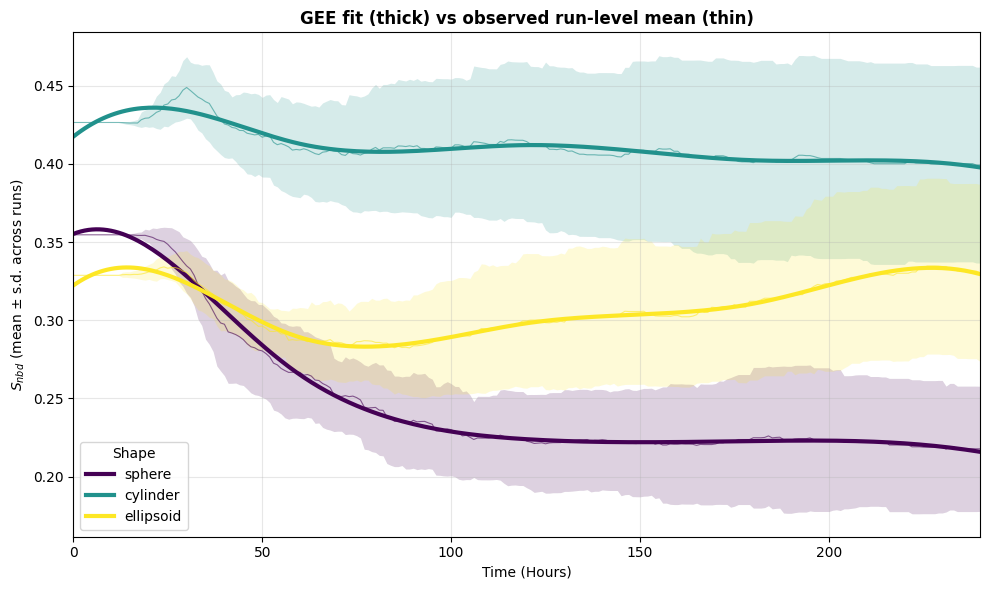

In [10]:


KEY = ['Time', 'CellID', 'Run']
SHAPES = ['sphere', 'cylinder', 'ellipsoid']
COLORS = {'sphere': '#440154', 'cylinder': '#21918c', 'ellipsoid': '#fde725'}


# ==========================================
# 1. PREPARE DATA (RUN-LEVEL S_nbd OF PRO-OOCYTES)
# ==========================================
def prepare_nbd_runlevel(data_dict, sample_interval=1):
    print(f"\n[1] PREPARING DATA (run-level means, sampling every {sample_interval} h)...")
    frames = []
    for shape, df in data_dict.items():
        germ = df.loc[(df['Feature'] == 'GERM') & (df['Value'] == 1), KEY].drop_duplicates()
        non_nurse = df.loc[(df['Feature'] == 'NurseActivation') & (df['Value'] == 0), KEY].drop_duplicates()
        pro = germ.merge(non_nurse, on=KEY, how='inner')

        nbd = (df.loc[df['Feature'] == 'NBD_Score', KEY + ['Value']]
                 .merge(pro, on=KEY, how='inner'))
        nbd = nbd[nbd['Time'] % sample_interval == 0]

        g = (nbd.groupby(['Run', 'Time'])['Value']
                .agg(Value='mean', n_cells='size').reset_index())
        g['Shape'] = shape
        g['Subject'] = shape + '_Run' + g['Run'].astype(int).astype(str)
        frames.append(g)

    out = pd.concat(frames, ignore_index=True)
    out['Time'] = out['Time'].astype(float)
    out['Shape'] = pd.Categorical(out['Shape'], categories=SHAPES, ordered=False)
    out = out.sort_values(['Subject', 'Time']).reset_index(drop=True)

    print(f"   Total observations: {len(out)}")
    print(f"   Unique subjects (runs): {out['Subject'].nunique()}")
    print(f"   Subjects per shape: {out.groupby('Shape', observed=True)['Subject'].nunique().to_dict()}")
    print(f"   Time range: {out['Time'].min():.0f}-{out['Time'].max():.0f} h")
    print(f"   Min / median pro-oocytes per run-time mean: "
          f"{out['n_cells'].min()} / {int(out['n_cells'].median())}")
    return out


# ==========================================
# 2. FIT MODEL (GAMMA GEE + B-SPLINES, RUN-LEVEL CLUSTERS)
# ==========================================
def fit_nbd_spline(df, dof=6, use_weights=False):
    print("\n[2] FITTING GEE (Gamma, log link) + B-SPLINES...")
    formula = f"Value ~ C(Shape, Treatment(reference='sphere')) * bs(Time, df={dof})"
    print(f"   Formula: {formula}")
    print(f"   Correlation: Exchangeable (run-level clustering), weights={use_weights}")
    try:
        model = smf.gee(formula, groups="Subject", data=df,
                        family=sm.families.Gamma(link=sm.families.links.log()),
                        cov_struct=sm.cov_struct.Exchangeable(),
                        weights=df['n_cells'].values if use_weights else None)
        result = model.fit()
        print("   ✓ Model converged")
        return result
    except Exception as e:
        print(f"   ❌ Model failed: {e}")
        return None


# ==========================================
# 3. TESTS AND EFFECT SIZES
# ==========================================
def joint_wald_tests(res):
    print("\n[3a] JOINT WALD TESTS (overall shape and shape x time)")
    print(res.wald_test_terms(scalar=True).summary_frame())


def pairwise_wald(res, shape):
    idx = [i for i, n in enumerate(res.params.index) if f'[T.{shape}]' in n]
    R = np.zeros((len(idx), len(res.params)))
    for r, i in enumerate(idx):
        R[r, i] = 1
    w = res.wald_test(R, scalar=True)
    return len(idx), float(w.statistic), float(w.pvalue)


def curve_summary(res, df, times=(0, 24, 48, 96, 168, 240), n_draws=2000, seed=0):
    di = res.model.data.design_info
    grid = np.arange(int(df['Time'].min()), int(df['Time'].max()) + 1, dtype=float)
    X = lambda s: np.asarray(build_design_matrices(
        [di], pd.DataFrame({'Shape': s, 'Time': grid}))[0])
    draws = np.random.default_rng(seed).multivariate_normal(
        res.params.values, res.cov_params().values, n_draws)
    mu = {s: np.exp(X(s) @ draws.T) for s in SHAPES}
    q = lambda a: np.percentile(a, [50, 2.5, 97.5]).round(3)

    print("\n[3b] PAIRWISE WALD TESTS vs SPHERE (main + all interaction terms)")
    for s in ['cylinder', 'ellipsoid']:
        k, chi2, p = pairwise_wald(res, s)
        print(f"   {s}: chi2({k}) = {chi2:.1f}, p = {p:.3g}")

    print("\n[3c] MODEL-PREDICTED S_nbd (median [95% CI])")
    for t in times:
        i = int(np.where(grid == t)[0][0])
        print(f"   t={t:>3} h  " + "  ".join(f"{s}: {q(mu[s][i])}" for s in SHAPES))

    print("\n[3d] RATIOS vs SPHERE (median [95% CI])")
    for s in ['cylinder', 'ellipsoid']:
        for t in times:
            i = int(np.where(grid == t)[0][0])
            print(f"   {s} / sphere @ {t:>3} h: {q(mu[s][i] / mu['sphere'][i])}")

    base = float(res.predict(pd.DataFrame({'Shape': ['sphere'], 'Time': [float(df['Time'].min())]})).iloc[0])
    print(f"\n   Model-predicted sphere S_nbd at t={df['Time'].min():.0f}: {base:.3f}")
    return mu


# ==========================================
# 4. VISUALIZE (OBSERVED RUN MEANS +/- SD vs FITTED CURVES)
# ==========================================
def visualize_nbd_results(res, df, save_path=None):
    print("\n[4] GENERATING VISUALIZATION...")
    grid = np.linspace(df['Time'].min(), df['Time'].max(), 241)
    fig, ax = plt.subplots(figsize=(10, 6))
    for s in SHAPES:
        sub = df[df['Shape'] == s]
        g = sub.groupby('Time')['Value'].agg(['mean', 'std']).reset_index()
        ax.fill_between(g['Time'], g['mean'] - g['std'], g['mean'] + g['std'],
                        color=COLORS[s], alpha=0.18, lw=0)
        ax.plot(g['Time'], g['mean'], color=COLORS[s], lw=0.8, alpha=0.6)
        pred = res.predict(pd.DataFrame({'Shape': s, 'Time': grid}))
        ax.plot(grid, pred, color=COLORS[s], lw=3, label=s)
    ax.set_xlabel("Time (Hours)")
    ax.set_ylabel(r"$S_{nbd}$ (mean $\pm$ s.d. across runs)")
    ax.set_title("GEE fit (thick) vs observed run-level mean (thin)", fontweight='bold')
    ax.set_xlim(df['Time'].min(), df['Time'].max())
    ax.legend(title='Shape', loc='best')
    ax.grid(alpha=0.3)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300)
    plt.show()


# ==========================================
# EXECUTION BLOCK
# ==========================================
glmm_df_nbd = prepare_nbd_runlevel(all_shape_data, sample_interval=1)
result_nbd = fit_nbd_spline(glmm_df_nbd, dof=6, use_weights=False)

if result_nbd is not None:
    print(result_nbd.summary())
    joint_wald_tests(result_nbd)
    mu_nbd = curve_summary(result_nbd, glmm_df_nbd)
    visualize_nbd_results(result_nbd, glmm_df_nbd)

In [11]:

def prepare_nbd_score_mean(data_dict, sample_interval=1):
    """
    Calculate mean NBD score across all non-nurse germ cells for each shape and time
    """
    all_records = []
    
    for shape, df in data_dict.items():
        # Filter germ cells
        germ_cells = df[df['Feature'] == 'GERM']
        valid_germs = germ_cells[germ_cells['Value'] == 1][['Time', 'CellID', 'Run']].drop_duplicates()

        non_nurse = df[df['Feature'] == 'NurseActivation']
        non_nurse = non_nurse[non_nurse['Value'] == 0][['Time', 'CellID', 'Run']].drop_duplicates()

        valid_prooocytes = valid_germs.merge(non_nurse, on=['Time', 'CellID', 'Run'], how='inner')
    
        # 2. Get NBD Scores
        nbd_data = df[df['Feature'] == 'NBD_Score']
        
        # 3. Merge to keep ONLY NBD scores that belong to valid Germ Cells
        #    (This eliminates the "noise" and zigzags)
        nbd_germ = nbd_data.merge(valid_prooocytes, on=['Time', 'CellID', 'Run'], how='inner')
        
        
        # Sample and group by time
        df_sampled = nbd_germ[nbd_germ['Time'] % sample_interval == 0].copy()
        
        # Calculate mean and std for each time point
        grouped = df_sampled.groupby('Time')['Value'].agg(['mean', 'std', 'count']).reset_index()
        grouped['Shape'] = shape
        grouped.columns = ['Time', 'NBD_Mean', 'NBD_Std', 'NBD_Count', 'Shape']
        
        all_records.append(grouped)
    
    return pd.concat(all_records, ignore_index=True)

In [12]:
def extract_cell_counts_from_trajectories(data_dict, sample_interval=1):
    """
    Extract nurse and pro-oocyte cell counts from raw trajectory data.
    Returns RUN-LEVEL data (not aggregated), consistent with NBD score analysis.
    
    Uses NurseActivation feature:
    - NurseActivation == 10 → Nurse cell
    - NurseActivation == 0 → Non-nurse/Pro-oocyte cell
    
    Parameters:
    -----------
    data_dict : dict
        {shape_name: DataFrame} from load_shape_data
    sample_interval : int
        Sample every N hours
    
    Returns:
    --------
    pd.DataFrame : Run-level format with [Shape, Time, Run, Nurse_Count, ProOocyte_Count, Total_Germ]
    """
    print("\n" + "="*80)
    print("EXTRACTING CELL COUNTS FROM RAW TRAJECTORY DATA (RUN-LEVEL)")
    print("="*80)
    
    all_records = []
    
    for shape, df in data_dict.items():
        print(f"\nProcessing {shape.upper()}...")
        
        # Get germ cells only (GERM == 1)
        germ_cells = df[df['Feature'] == 'GERM']
        valid_germs = germ_cells[germ_cells['Value'] == 1][['Time', 'CellID', 'Run']].drop_duplicates()
        
        # Get nurse activation status
        nurse_activation = df[df['Feature'] == 'NurseActivation']
        
        # Merge to get nurse status for germ cells
        germ_with_nurse = valid_germs.merge(
            nurse_activation[['Time', 'CellID', 'Run', 'Value']], 
            on=['Time', 'CellID', 'Run'], 
            how='inner'
        )
        germ_with_nurse.rename(columns={'Value': 'NurseActivation'}, inplace=True)
        
        # Filter to sampled times
        sampled_df = germ_with_nurse[germ_with_nurse['Time'] % sample_interval == 0].copy()
        
        # Count cells by time and run (keep run-level data!)
        for (time, run), group in sampled_df.groupby(['Time', 'Run']):
            nurse_count = len(group[group['NurseActivation'] == 10])
            prooocyte_count = len(group[group['NurseActivation'] == 0])
            
            all_records.append({
                'Shape': shape,
                'Time': time,
                'Run': run,
                'Nurse_Count': nurse_count,
                'ProOocyte_Count': prooocyte_count,
                'Total_Germ': nurse_count + prooocyte_count
            })
        
        print(f"  ✓ Extracted {len([r for r in all_records if r['Shape'] == shape])} run-level observations")
    
    # Combine all shapes
    result_df = pd.DataFrame(all_records)
    
    print(f"\n✓ Total run-level observations: {len(result_df)}")
    print(f"  Shapes: {result_df['Shape'].nunique()}")
    print(f"  Unique runs per shape: {result_df.groupby('Shape')['Run'].nunique().to_dict()}")
    print(f"  Time points: {result_df['Time'].nunique()}")
    print(f"  Time range: {result_df['Time'].min():.1f} - {result_df['Time'].max():.1f}h")
    
    return result_df


In [13]:

def analyze_cell_count_feature(
    cell_counts_raw, feature_name="Nurse", spline_df=6
):
  """Run GEE analysis on RUN-LEVEL cell count data using Poisson family and B-splines.

  Parameters:
  -----------
  cell_counts_raw : DataFrame
      Run-level cell count data with columns [Shape, Time, Run, Nurse_Count,
      ProOocyte_Count]
  feature_name : str
      'Nurse' or 'ProOocyte'
  spline_df : int
      Degrees of freedom for B-spline (default=6)
  """
  print(f"\n" + "=" * 80)
  print(
      f"GEE ANALYSIS: {feature_name.upper()} CELL COUNTS (POISSON + B-SPLINES)"
  )
  print("=" * 80)

  # Prepare data for GEE
  col_name = f"{feature_name}_Count"

  glmm_data = []
  for _, row in cell_counts_raw.iterrows():
    glmm_data.append({
        "Shape": row["Shape"],
        "Time": row["Time"],
        "Value": int(row[col_name]),  # Raw discrete integer count (0, 1, 2, ...)
        "Run": row["Run"],
        "Subject": f"{row['Shape']}_Run{int(row['Run'])}",
    })

  df = pd.DataFrame(glmm_data)

  # Set categorical with 'sphere' as reference baseline
  df["Shape"] = pd.Categorical(
      df["Shape"], categories=["sphere", "cylinder", "ellipsoid"], ordered=False
  )

  print(f"\nData structure:")
  print(f"  Total observations: {len(df)}")
  print(f"  Unique subjects (runs): {df['Subject'].nunique()}")
  print(
      f"  Subjects per shape:"
      f" {df.groupby('Shape')['Subject'].nunique().to_dict()}"
  )
  print(f"  Time points: {df['Time'].nunique()}")

  # Formula using B-splines for flexible temporal trajectories
  formula = f"Value ~ C(Shape, Treatment(reference='sphere')) * bs(Time, df={spline_df})"

  print(f"\nFormula: {formula}")
  print("Family: Poisson (Log Link)")
  print("Correlation structure: Exchangeable (run-level clustering)")

  try:
    fam = sm.families.Poisson(link=sm.families.links.Log())
    model = smf.gee(
        formula,
        groups="Subject",
        data=df,
        family=fam,
        cov_struct=sm.cov_struct.Exchangeable(),
    )

    result = model.fit()
    print("✓ Model Converged Successfully\n")
    print(result.summary())

    # --- JOINT WALD TEST (TYPE III ANALYSIS FOR SPLINES) ---
    print("\n" + "=" * 80)
    print(f"JOINT WALD TEST (OVERALL SHAPE & INTERACTION EFFECTS)")
    print("=" * 80)

    wald_results = result.wald_test_terms(scalar=True)
    print(wald_results)

    # --- EXPECTED INITIAL COUNT AT T=0 ---
    # Verification that the artificial t=0 intercept is resolved
    baseline_intercept = result.params["Intercept"]
    expected_t0 = np.exp(baseline_intercept)
    print(f"\nModel Predicted Baseline Count at t=0 (Sphere): {expected_t0:.4f}")

    return result

  except Exception as e:
    print(f"❌ Model Failed: {e}")
    return None


# ==========================================
# EXECUTE COMBINED ANALYSIS (TRAJECTORY-LEVEL)
# ==========================================

In [14]:

def plot_combined_cell_counts_nbd(all_shape_data, sample_interval=1):
    """
    Create comprehensive plots:
    1. Nurse cell count evolution
    2. Pro-oocyte cell count evolution
    3. Germ cell NBD score evolution
    
    Uses run-level data and calculates mean/std for visualization
    """
    print("\n" + "="*80)
    print("CREATING COMBINED CELL COUNT + NBD SCORE PLOT")
    print("="*80)
    
    # Extract run-level cell counts
    cell_counts_raw = extract_cell_counts_from_trajectories(all_shape_data, sample_interval=sample_interval)
    
    if cell_counts_raw is None or cell_counts_raw.empty:
        print("❌ No cell count data loaded!")
        return None, None
    
    # Aggregate for plotting (mean ± std across runs)
    cell_counts_agg = cell_counts_raw.groupby(['Shape', 'Time']).agg({
        'Nurse_Count': ['mean', 'std'],
        'ProOocyte_Count': ['mean', 'std'],
        'Total_Germ': ['mean', 'std']
    }).reset_index()
    
    cell_counts_agg.columns = ['Shape', 'Time', 'Nurse_Mean', 'Nurse_Std',
                                'ProOocyte_Mean', 'ProOocyte_Std', 'Germ_Mean', 'Germ_Std']
    
    # Prepare NBD score data
    nbd_scores = prepare_nbd_score_mean(all_shape_data, sample_interval=sample_interval)
    
    shapes = ['sphere', 'cylinder', 'ellipsoid']
    cmap = plt.get_cmap('viridis')  # or 'plasma'
    colors = {shape: cmap(i / (len(shapes) - 1)) for i, shape in enumerate(shapes)}
    
    linestyles = {
        'sphere': '-',
        'cylinder': '-',
        'ellipsoid': '-',
    }
    
    # Common settings for the shaded/hatched regions
    hatched_shape = 'cylinder'
    shape_alpha_dict = {"sphere": 0.25, "ellipsoid": 0.3}
    
    # ==================== PLOT 1: NURSE CELL COUNTS ====================
    fig, ax1 = plt.subplots(1, 1, figsize=(16, 8), sharex=True)
    
    for shape in shapes:
        data = cell_counts_agg[cell_counts_agg['Shape'] == shape]
        x = data['Time']
        y = data['Nurse_Mean']
        s = data['Nurse_Std'].fillna(0)
        
        # Mean Line
        ax1.plot(x, y, color=colors[shape], linewidth=3.0, 
                 label=shape.capitalize(), linestyle=linestyles[shape], zorder=5)
                 
        # Variance Shading
        if shape == hatched_shape:
            ax1.fill_between(x, y - s, y + s, facecolor='none', edgecolor=colors[shape], 
                             hatch='|', alpha=0.3, linewidth=0, zorder=3)
            ax1.plot(x, y - s, color=colors[shape], linewidth=1.0, linestyle='--', alpha=0.6, zorder=4)
            ax1.plot(x, y + s, color=colors[shape], linewidth=1.0, linestyle='--', alpha=0.6, zorder=4)
        else:
            ax1.fill_between(x, y - s, y + s, color=colors[shape], 
                             alpha=shape_alpha_dict.get(shape, 0.2), linewidth=0, zorder=1)
    
    ax1.set_xlabel('Time (Hours)', fontsize=24, fontweight='bold', fontfamily='Times New Roman')
    ax1.set_ylabel('Nurse Cell Count (Mean ± Std)', fontsize=24, fontweight='bold', fontfamily='Times New Roman')
    ax1.set_axisbelow(True)
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim(left=0, right=240)
    ax1.set_xticks(np.arange(0, 241, 24))
    ax1.tick_params(axis='both', labelsize=24)
    
    for label in ax1.get_xticklabels() + ax1.get_yticklabels():
        label.set_fontfamily('Times New Roman')
        
    # ax1.legend(frameon=True, fontsize=20, loc='best', edgecolor='black')
    
    plt.tight_layout()
    plt.savefig(COMPARISON_OUT_DIR / 'population_dynamics_shape_comparison_nurse.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # ==================== PLOT 2: PRO-OOCYTE COUNTS ====================
    fig, ax2 = plt.subplots(1, 1, figsize=(16, 8), sharex=True)
    
    for shape in shapes:
        data = cell_counts_agg[cell_counts_agg['Shape'] == shape]
        x = data['Time']
        y = data['ProOocyte_Mean']
        s = data['ProOocyte_Std'].fillna(0)
        
        # Mean Line
        ax2.plot(x, y, color=colors[shape], linewidth=3.0, 
                 label=shape.capitalize(), linestyle=linestyles[shape], zorder=5)
                 
        # Variance Shading
        if shape == hatched_shape:
            ax2.fill_between(x, y - s, y + s, facecolor='none', edgecolor=colors[shape], 
                             hatch='|', alpha=0.3, linewidth=0, zorder=3)
            ax2.plot(x, y - s, color=colors[shape], linewidth=1.0, linestyle='--', alpha=0.6, zorder=4)
            ax2.plot(x, y + s, color=colors[shape], linewidth=1.0, linestyle='--', alpha=0.6, zorder=4)
        else:
            ax2.fill_between(x, y - s, y + s, color=colors[shape], 
                             alpha=shape_alpha_dict.get(shape, 0.2), linewidth=0, zorder=1)
    
    ax2.set_xlabel('Time (Hours)', fontsize=24, fontweight='bold', fontfamily='Times New Roman')
    ax2.set_ylabel('Non-nurse Germ Cell Count (Mean ± Std)', fontsize=24, fontweight='bold', fontfamily='Times New Roman')
    ax2.set_axisbelow(True)
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim(left=0, right=240)
    ax2.set_xticks(np.arange(0, 241, 24))
    ax2.tick_params(axis='both', labelsize=24)
    
    for label in ax2.get_xticklabels() + ax2.get_yticklabels():
        label.set_fontfamily('Times New Roman')
        
    # ax2.legend(frameon=True, fontsize=20, loc='best', edgecolor='black')
    
    plt.tight_layout()
    plt.savefig(COMPARISON_OUT_DIR / 'population_dynamics_shape_comparison_prooocyte.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # ==================== PLOT 3: NBD SCORE ====================
    fig, ax3 = plt.subplots(1, 1, figsize=(16, 8), sharex=True)
    
    for shape in shapes:
        data = nbd_scores[nbd_scores['Shape'] == shape]
        x = data['Time']
        y = data['NBD_Mean']
        s = data['NBD_Std'].fillna(0)
        
        # Mean Line
        ax3.plot(x, y, color=colors[shape], linewidth=3.0, 
                 label=shape.capitalize(), linestyle=linestyles[shape], zorder=5)
        
        # Variance Shading
        if shape == hatched_shape:
            ax3.fill_between(x, y - s, y + s, facecolor='none', edgecolor=colors[shape], 
                             hatch='|', alpha=0.3, linewidth=0, zorder=3)
            ax3.plot(x, y - s, color=colors[shape], linewidth=1.0, linestyle='--', alpha=0.6, zorder=4)
            ax3.plot(x, y + s, color=colors[shape], linewidth=1.0, linestyle='--', alpha=0.6, zorder=4)
        else:
            ax3.fill_between(x, y - s, y + s, color=colors[shape], 
                             alpha=shape_alpha_dict.get(shape, 0.2), linewidth=0, zorder=1)

    ax3.set_xlabel('Time (Hours)', fontsize=24, fontweight='bold', fontfamily='Times New Roman')
    ax3.set_ylabel('NBD Score (Mean ± Std)', fontsize=24, fontweight='bold', fontfamily='Times New Roman')
    ax3.set_axisbelow(True)
    ax3.grid(True, alpha=0.3)
    ax3.set_xlim(left=0, right=240)
    ax3.set_xticks(np.arange(0, 241, 24))
    ax3.tick_params(axis='both', labelsize=24)

    for label in ax3.get_xticklabels() + ax3.get_yticklabels():
        label.set_fontfamily('Times New Roman')

    # ax3.legend(frameon=True, fontsize=20, loc='best', edgecolor='black')
    
    plt.tight_layout()
    plt.savefig(COMPARISON_OUT_DIR / 'dynamics_shape_comparison_nbd.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Combined plots generated successfully!")
    
    return cell_counts_raw, nbd_scores


################################################################################
COMBINED CELL COUNT + NBD SCORE ANALYSIS (RUN-LEVEL TRAJECTORIES)
################################################################################

CREATING COMBINED CELL COUNT + NBD SCORE PLOT

EXTRACTING CELL COUNTS FROM RAW TRAJECTORY DATA (RUN-LEVEL)

Processing SPHERE...
  ✓ Extracted 8435 run-level observations

Processing CYLINDER...
  ✓ Extracted 8435 run-level observations

Processing ELLIPSOID...
  ✓ Extracted 8435 run-level observations

✓ Total run-level observations: 25305
  Shapes: 3
  Unique runs per shape: {'cylinder': 35, 'ellipsoid': 35, 'sphere': 35}
  Time points: 241
  Time range: 0.0 - 240.0h


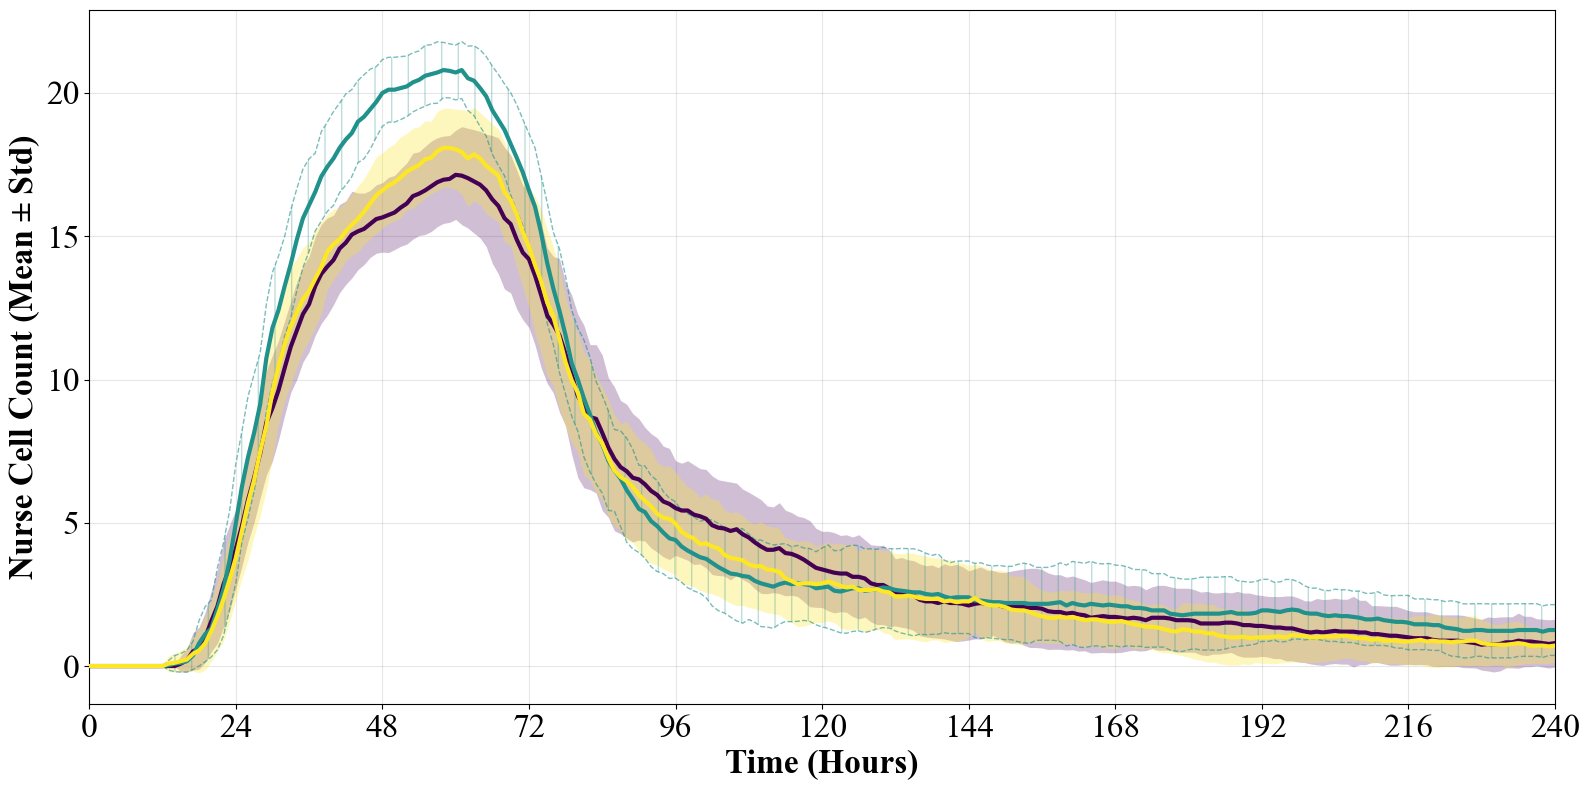

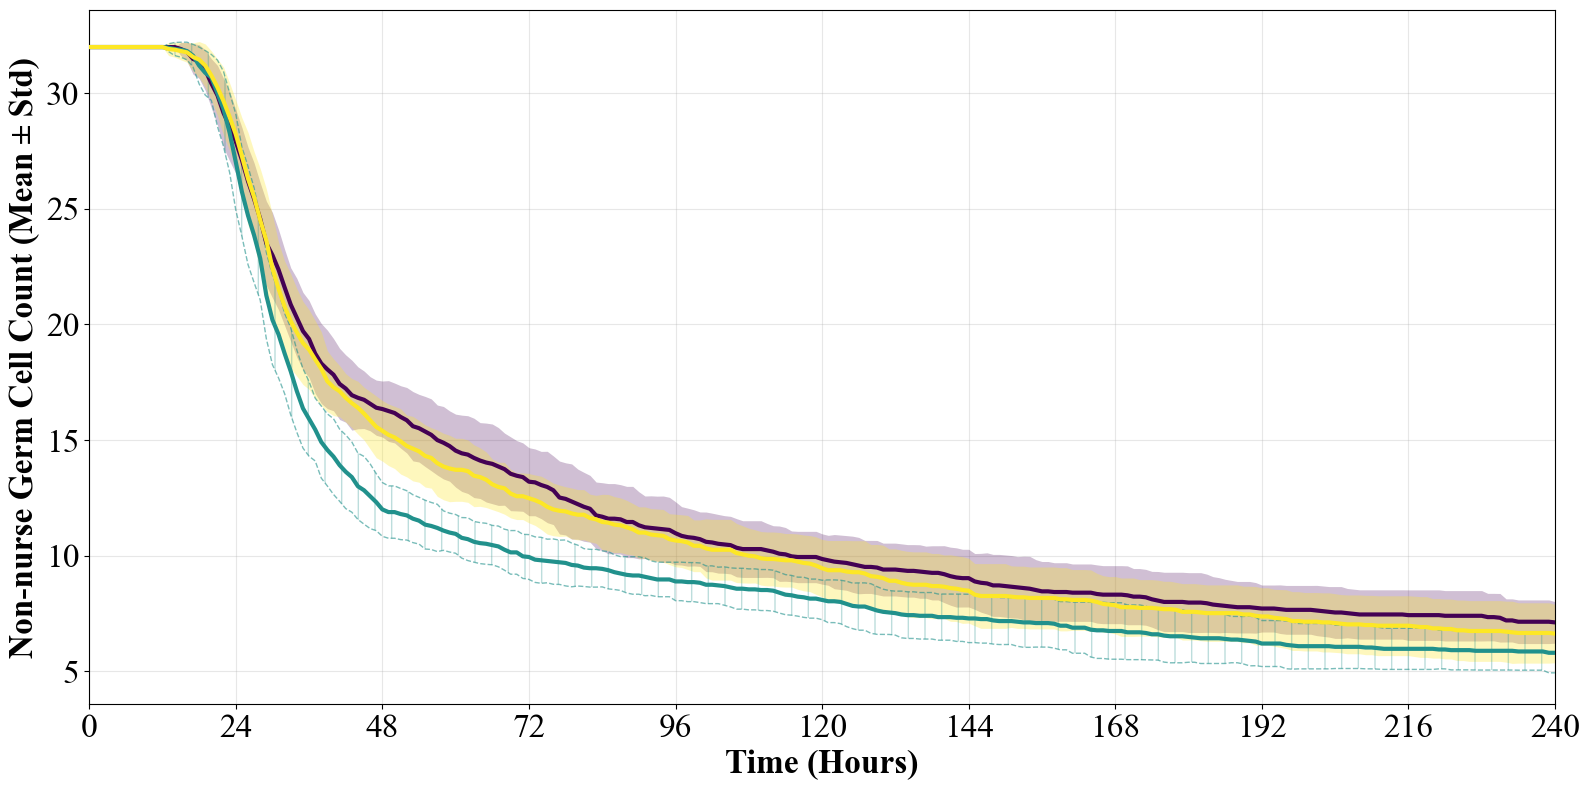

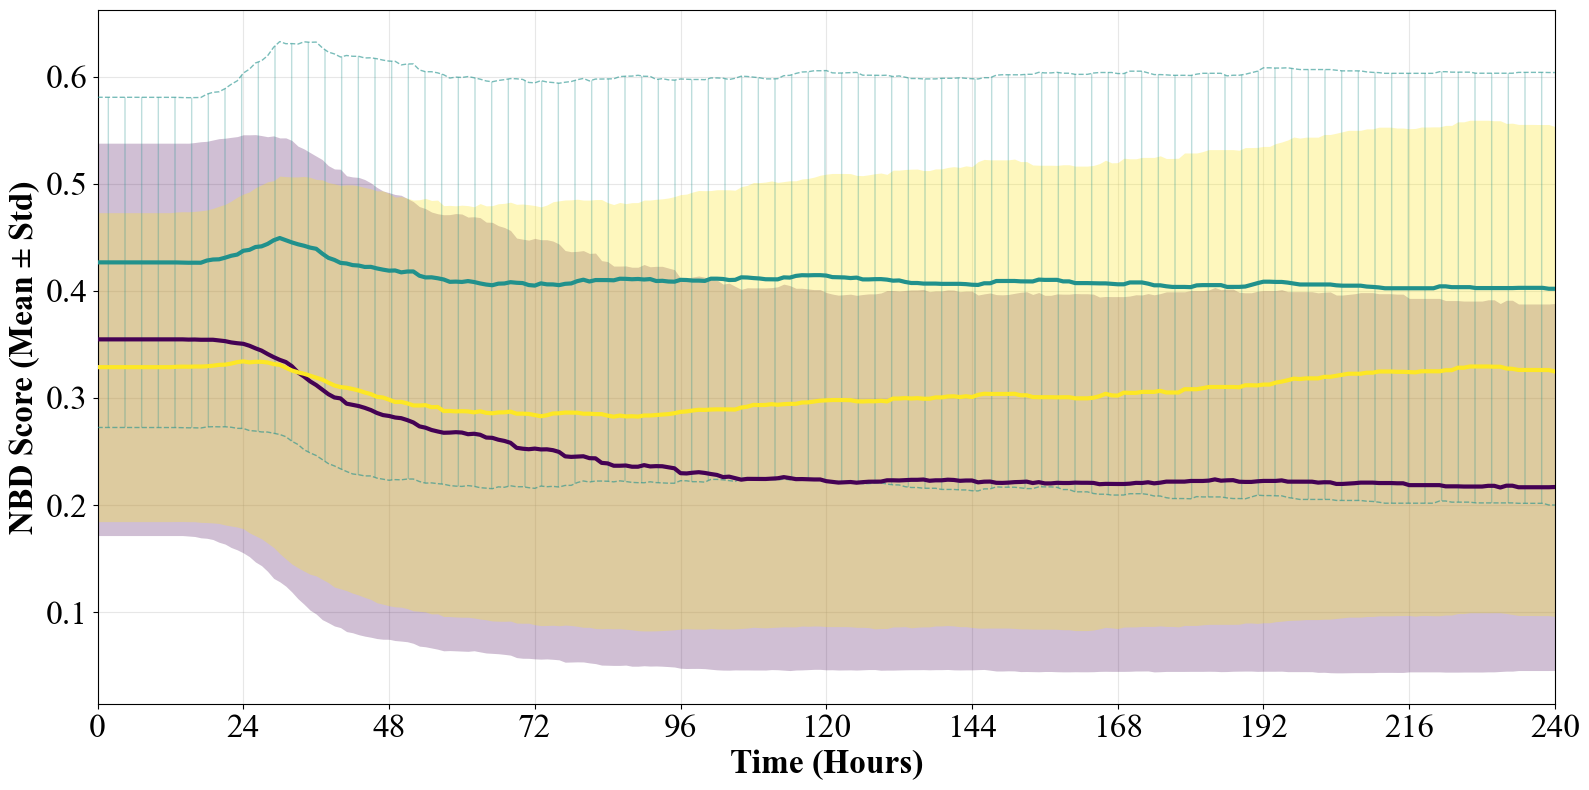

✓ Combined plots generated successfully!


████████████████████████████████████████████████████████████████████████████████
STATISTICAL ANALYSIS: NURSE CELLS (RUN-LEVEL)
████████████████████████████████████████████████████████████████████████████████

GEE ANALYSIS: NURSE CELL COUNTS (POISSON + B-SPLINES)

Data structure:
  Total observations: 25305
  Unique subjects (runs): 105
  Subjects per shape: {'sphere': 35, 'cylinder': 35, 'ellipsoid': 35}
  Time points: 241

Formula: Value ~ C(Shape, Treatment(reference='sphere')) * bs(Time, df=6)
Family: Poisson (Log Link)
Correlation structure: Exchangeable (run-level clustering)
✓ Model Converged Successfully

                               GEE Regression Results                              
Dep. Variable:                       Value   No. Observations:                25305
Model:                                 GEE   No. clusters:                      105
Method:                        Generalized   Min. cluster size:                 241
 

In [15]:

print("\n" + "#"*80)
print("COMBINED CELL COUNT + NBD SCORE ANALYSIS (RUN-LEVEL TRAJECTORIES)")
print("#"*80)

# Generate combined plot and get run-level data
cell_counts_raw, nbd_scores_df = plot_combined_cell_counts_nbd(all_shape_data, sample_interval=1)

# Analyze Nurse Cells (using run-level data)
print("\n\n" + "█"*80)
print("STATISTICAL ANALYSIS: NURSE CELLS (RUN-LEVEL)")
print("█"*80)
nurse_result = analyze_cell_count_feature(cell_counts_raw, 'Nurse')

# Analyze Pro-oocyte Cells (using run-level data)
print("\n\n" + "█"*80)
print("STATISTICAL ANALYSIS: PRO-OOCYTE CELLS (RUN-LEVEL)")
print("█"*80)
prooocyte_result = analyze_cell_count_feature(cell_counts_raw, 'ProOocyte')

print("\n\n" + "#"*80)
print("ANALYSIS COMPLETE!")
print("#"*80)